# CA1 Machine Learning
### Ciaran Lynch sba26096

Predicting Football Over 2.5 goals per game from the English Premier League from 2020/2021 season to 2025/26
Using Machine Learning Classification Models

In [920]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np

## Data Preparation

The goal at Data Preparation stage is to import the 6 csv files for The six Premier League years from 2020/2021 to 2025/26, into a dataframe
The Dataframes will be called:
df_PL_2020 = 2020/21 season
df_PL2021 = 2021/22 season
df_PL2022 = 2022/23 season
df_PL_2023 = 2023/24 season
df_PL2024 = 2024/25 season
df_PL_2025 = 2025/26 season  

source: https://football-data.co.uk/data.php  

This is a publicly available repository containing the required historical match statistics.  
    
The data held within the csv files include important match data, such as, goals scored, shots on target, home goals, away goals and match results.  
    
These variables will be relevant to the proposed business problem as they provide the information required for machine learning models to identify patterns associated with predicting football match outcomes.  
    
The data will be used solely for research and academic purposes in accordance with the website’s own restrictions.

## Create a Function to: 
Read the original csv files
Keep only required columns
Rename columns to make it more readable
Create new columns for Half Time Goals and Full Time Goals
Create a Dictionary to replace League name from the csv files

In [921]:
def prepare_league(file_name): # file_name is a parameter given to the function
    
    # read in csv
    df = pd.read_csv(file_name)
    
    # rename columns
    df = df.rename(columns={
    "Div": "League",
    "HomeTeam": "Home_Team",
    "AwayTeam": "Away_Team",
    "FTHG": "FT_Home_Goals",
    "FTAG": "FT_Away_Goals",
    "FTR": "Result",
    "HTHG": "HT_Home_Goals",
    "HTAG": "HT_Away_Goals",
    "HST": "Home_Shots_On_Target",
    "AST": "Away_Shots_On_Target",
    "HC": "Home_Corners",
    "AC": "Away_Corners",

    } 
    )
    
    # create duplicate dataframe with required columns only
    df = df[
        ["Date", 
          "League", 
          "Home_Team", 
          "Away_Team", 
          "HT_Home_Goals",
          "HT_Away_Goals", 
          "FT_Home_Goals", 
          "FT_Away_Goals", 
          "Home_Shots_On_Target",
          "Away_Shots_On_Target",
          "Home_Corners",
          "Away_Corners"]
          ].copy()
    
    # create new columns for half time and full time goals
    df["HT_Goals"] = (
    df["HT_Home_Goals"] + df["HT_Away_Goals"] 
    )

    df["FT_Goals"] = (
    df["FT_Home_Goals"] + df["FT_Away_Goals"] 
    )

    # create new columns for Total Shots on Target
    df["Total_Shots_On_Target"] = (
    df["Home_Shots_On_Target"] + df["Away_Shots_On_Target"] 
    )

    # create new columns for Total Corners
    df["Total_Corners"] = (
    df["Home_Corners"] + df["Away_Corners"] 
    )
    # Create a Dictionary to replace League names from the csv files.  This will make it more readable once i created a merged dataframe
    df["League"] = df["League"].replace( 
        {
            "E0": "English Premier League",
        }

   
    )
            

    return df
    


Call the Premier League 2020/2021 using the prepare league function
Run Data Preparation

In [922]:
df_PL_2020 = prepare_league("Premier_League_2020_2021.csv") 

In [923]:
df_PL_2020.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,12/09/2020,English Premier League,Fulham,Arsenal,0,1,0,3,2,6,2,3,1,3,8,5
1,12/09/2020,English Premier League,Crystal Palace,Southampton,1,0,1,0,3,5,7,3,1,1,8,10
2,12/09/2020,English Premier League,Liverpool,Leeds,3,2,4,3,6,3,9,0,5,7,9,9
3,12/09/2020,English Premier League,West Ham,Newcastle,0,0,0,2,3,2,8,7,0,2,5,15
4,13/09/2020,English Premier League,West Brom,Leicester,0,0,0,3,1,7,2,5,0,3,8,7


In [924]:
df_PL_2020.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Date                   380 non-null    str  
 1   League                 380 non-null    str  
 2   Home_Team              380 non-null    str  
 3   Away_Team              380 non-null    str  
 4   HT_Home_Goals          380 non-null    int64
 5   HT_Away_Goals          380 non-null    int64
 6   FT_Home_Goals          380 non-null    int64
 7   FT_Away_Goals          380 non-null    int64
 8   Home_Shots_On_Target   380 non-null    int64
 9   Away_Shots_On_Target   380 non-null    int64
 10  Home_Corners           380 non-null    int64
 11  Away_Corners           380 non-null    int64
 12  HT_Goals               380 non-null    int64
 13  FT_Goals               380 non-null    int64
 14  Total_Shots_On_Target  380 non-null    int64
 15  Total_Corners          380 non-null    int64
dtypes

In [925]:
print(df_PL_2020.shape)

(380, 16)


In [926]:
df_PL_2020.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2020_2021

Call the Premier League 2021/2022 using the prepare league function
Run Data Preparation

In [927]:
df_PL_2021 = prepare_league("Premier_League_2021_2022.csv") 

In [928]:
df_PL_2021.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,13/08/2021,English Premier League,Brentford,Arsenal,1,0,2,0,3,4,2,5,1,2,7,7
1,14/08/2021,English Premier League,Man United,Leeds,1,0,5,1,8,3,5,4,1,6,11,9
2,14/08/2021,English Premier League,Burnley,Brighton,1,0,1,2,3,8,7,6,1,3,11,13
3,14/08/2021,English Premier League,Chelsea,Crystal Palace,2,0,3,0,6,1,5,2,2,3,7,7
4,14/08/2021,English Premier League,Everton,Southampton,0,1,3,1,6,3,6,8,1,4,9,14


In [929]:
df_PL_2021.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Date                   380 non-null    str  
 1   League                 380 non-null    str  
 2   Home_Team              380 non-null    str  
 3   Away_Team              380 non-null    str  
 4   HT_Home_Goals          380 non-null    int64
 5   HT_Away_Goals          380 non-null    int64
 6   FT_Home_Goals          380 non-null    int64
 7   FT_Away_Goals          380 non-null    int64
 8   Home_Shots_On_Target   380 non-null    int64
 9   Away_Shots_On_Target   380 non-null    int64
 10  Home_Corners           380 non-null    int64
 11  Away_Corners           380 non-null    int64
 12  HT_Goals               380 non-null    int64
 13  FT_Goals               380 non-null    int64
 14  Total_Shots_On_Target  380 non-null    int64
 15  Total_Corners          380 non-null    int64
dtypes

In [930]:
print(df_PL_2021.shape)

(380, 16)


In [931]:
df_PL_2021.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2021_2022

Call the Premier League 2022/2023 using the prepare league function
Run Data Preparation

In [932]:
df_PL_2022 = prepare_league("Premier_League_2022_2023.csv") 

In [933]:
df_PL_2022.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,05/08/2022,English Premier League,Crystal Palace,Arsenal,0,1,0,2,2,2,3,5,1,2,4,8
1,06/08/2022,English Premier League,Fulham,Liverpool,1,0,2,2,3,4,4,4,1,4,7,8
2,06/08/2022,English Premier League,Bournemouth,Aston Villa,1,0,2,0,3,2,5,5,1,2,5,10
3,06/08/2022,English Premier League,Leeds,Wolves,1,1,2,1,4,6,6,4,2,3,10,10
4,06/08/2022,English Premier League,Newcastle,Nott'm Forest,0,0,2,0,10,0,11,1,0,2,10,12


In [934]:
df_PL_2022.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Date                   380 non-null    str  
 1   League                 380 non-null    str  
 2   Home_Team              380 non-null    str  
 3   Away_Team              380 non-null    str  
 4   HT_Home_Goals          380 non-null    int64
 5   HT_Away_Goals          380 non-null    int64
 6   FT_Home_Goals          380 non-null    int64
 7   FT_Away_Goals          380 non-null    int64
 8   Home_Shots_On_Target   380 non-null    int64
 9   Away_Shots_On_Target   380 non-null    int64
 10  Home_Corners           380 non-null    int64
 11  Away_Corners           380 non-null    int64
 12  HT_Goals               380 non-null    int64
 13  FT_Goals               380 non-null    int64
 14  Total_Shots_On_Target  380 non-null    int64
 15  Total_Corners          380 non-null    int64
dtypes

In [935]:
print(df_PL_2022.shape)

(380, 16)


In [936]:
df_PL_2022.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2022_2023

Call the Premier League 2023/2024 using the prepare league function
Run Data Preparation

In [937]:
df_PL_2023 = prepare_league("Premier_League_2023_2024.csv") 

In [938]:
df_PL_2023.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,11/08/2023,English Premier League,Burnley,Man City,0,2,0,3,1,8,6,5,2,3,9,11
1,12/08/2023,English Premier League,Arsenal,Nott'm Forest,2,0,2,1,7,2,8,3,2,3,9,11
2,12/08/2023,English Premier League,Bournemouth,West Ham,0,0,1,1,5,3,10,4,0,2,8,14
3,12/08/2023,English Premier League,Brighton,Luton,1,0,4,1,12,3,6,7,1,5,15,13
4,12/08/2023,English Premier League,Everton,Fulham,0,0,0,1,9,2,10,4,0,1,11,14


In [939]:
df_PL_2023.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Date                   380 non-null    str  
 1   League                 380 non-null    str  
 2   Home_Team              380 non-null    str  
 3   Away_Team              380 non-null    str  
 4   HT_Home_Goals          380 non-null    int64
 5   HT_Away_Goals          380 non-null    int64
 6   FT_Home_Goals          380 non-null    int64
 7   FT_Away_Goals          380 non-null    int64
 8   Home_Shots_On_Target   380 non-null    int64
 9   Away_Shots_On_Target   380 non-null    int64
 10  Home_Corners           380 non-null    int64
 11  Away_Corners           380 non-null    int64
 12  HT_Goals               380 non-null    int64
 13  FT_Goals               380 non-null    int64
 14  Total_Shots_On_Target  380 non-null    int64
 15  Total_Corners          380 non-null    int64
dtypes

In [940]:
print(df_PL_2023.shape)

(380, 16)


In [941]:
df_PL_2023.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2020_2021

Call the Premier League 2024/2025 using the prepare league function
Run Data Preparation

In [942]:
df_PL_2024 = prepare_league("Premier_League_2024_2025.csv") 

In [943]:
df_PL_2024.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,16/08/2024,English Premier League,Man United,Fulham,0,0,1,0,5,2,7,8,0,1,7,15
1,17/08/2024,English Premier League,Ipswich,Liverpool,0,0,0,2,2,5,2,10,0,2,7,12
2,17/08/2024,English Premier League,Arsenal,Wolves,1,0,2,0,6,3,8,2,1,2,9,10
3,17/08/2024,English Premier League,Everton,Brighton,0,1,0,3,1,5,1,5,1,3,6,6
4,17/08/2024,English Premier League,Newcastle,Southampton,1,0,1,0,1,4,3,12,1,1,5,15


In [944]:
df_PL_2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Date                   380 non-null    str  
 1   League                 380 non-null    str  
 2   Home_Team              380 non-null    str  
 3   Away_Team              380 non-null    str  
 4   HT_Home_Goals          380 non-null    int64
 5   HT_Away_Goals          380 non-null    int64
 6   FT_Home_Goals          380 non-null    int64
 7   FT_Away_Goals          380 non-null    int64
 8   Home_Shots_On_Target   380 non-null    int64
 9   Away_Shots_On_Target   380 non-null    int64
 10  Home_Corners           380 non-null    int64
 11  Away_Corners           380 non-null    int64
 12  HT_Goals               380 non-null    int64
 13  FT_Goals               380 non-null    int64
 14  Total_Shots_On_Target  380 non-null    int64
 15  Total_Corners          380 non-null    int64
dtypes

In [945]:
print(df_PL_2024.shape)

(380, 16)


In [946]:
df_PL_2024.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2024_2025

Call the Premier League 2025/2026 using the prepare league function
Run Data Preparation

In [947]:
df_PL_2025 = prepare_league("Premier_League_2025_2026.csv") 

In [948]:
df_PL_2025.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,15/08/2025,English Premier League,Liverpool,Bournemouth,1,0,4,2,10,3,6,7,1,6,13,13
1,16/08/2025,English Premier League,Aston Villa,Newcastle,0,0,0,0,3,3,3,6,0,0,6,9
2,16/08/2025,English Premier League,Brighton,Fulham,0,0,1,1,4,2,4,3,0,2,6,7
3,16/08/2025,English Premier League,Sunderland,West Ham,0,0,3,0,5,4,5,7,0,3,9,12
4,16/08/2025,English Premier League,Tottenham,Burnley,1,0,3,0,6,4,6,5,1,3,10,11


In [949]:
df_PL_2025.info()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Date                   380 non-null    str  
 1   League                 380 non-null    str  
 2   Home_Team              380 non-null    str  
 3   Away_Team              380 non-null    str  
 4   HT_Home_Goals          380 non-null    int64
 5   HT_Away_Goals          380 non-null    int64
 6   FT_Home_Goals          380 non-null    int64
 7   FT_Away_Goals          380 non-null    int64
 8   Home_Shots_On_Target   380 non-null    int64
 9   Away_Shots_On_Target   380 non-null    int64
 10  Home_Corners           380 non-null    int64
 11  Away_Corners           380 non-null    int64
 12  HT_Goals               380 non-null    int64
 13  FT_Goals               380 non-null    int64
 14  Total_Shots_On_Target  380 non-null    int64
 15  Total_Corners          380 non-null    int64
dtypes

In [950]:
print(df_PL_2025.shape)

(380, 16)


In [951]:
df_PL_2025.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2025_2026

## Create an Integrated Football Dataset

Concat all dataFrames into 1 Master File

How to guide was used following the pandas documentation:  
https://pandas.pydata.org/pandas-docs/stable/user_guide/merging.html


In [952]:
frames = [df_PL_2020, df_PL_2021, df_PL_2022, df_PL_2023, df_PL_2024, df_PL_2025]

In [953]:
df_PL_Master = pd.concat(frames,ignore_index=True) 

## Run Data Preparation

In [954]:
df_PL_Master.sample(10)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
1998,02/11/2025,English Premier League,Man City,Bournemouth,2,1,3,1,8,5,10,4,3,4,13,14
278,13/03/2021,English Premier League,Crystal Palace,West Brom,1,0,1,0,4,1,3,2,1,1,5,5
578,15/01/2022,English Premier League,Aston Villa,Man United,0,1,2,2,9,6,3,6,1,4,15,9
2173,28/02/2026,English Premier League,Burnley,Brentford,1,3,3,4,3,7,4,8,4,7,10,12
427,19/09/2021,English Premier League,Brighton,Leicester,1,0,2,1,5,3,4,9,1,3,8,13
2062,20/12/2025,English Premier League,Brighton,Sunderland,0,0,0,0,4,6,3,4,0,0,10,7
452,16/10/2021,English Premier League,Leicester,Man United,1,1,4,2,11,6,4,3,2,6,17,7
1143,12/08/2023,English Premier League,Brighton,Luton,1,0,4,1,12,3,6,7,1,5,15,13
385,14/08/2021,English Premier League,Leicester,Wolves,1,0,1,0,5,3,5,4,1,1,8,9
1994,01/11/2025,English Premier League,Nott'm Forest,Man United,0,1,2,2,3,7,8,5,1,4,10,13


In [955]:
df_PL_Master.info()

<class 'pandas.DataFrame'>
RangeIndex: 2280 entries, 0 to 2279
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Date                   2280 non-null   str  
 1   League                 2280 non-null   str  
 2   Home_Team              2280 non-null   str  
 3   Away_Team              2280 non-null   str  
 4   HT_Home_Goals          2280 non-null   int64
 5   HT_Away_Goals          2280 non-null   int64
 6   FT_Home_Goals          2280 non-null   int64
 7   FT_Away_Goals          2280 non-null   int64
 8   Home_Shots_On_Target   2280 non-null   int64
 9   Away_Shots_On_Target   2280 non-null   int64
 10  Home_Corners           2280 non-null   int64
 11  Away_Corners           2280 non-null   int64
 12  HT_Goals               2280 non-null   int64
 13  FT_Goals               2280 non-null   int64
 14  Total_Shots_On_Target  2280 non-null   int64
 15  Total_Corners          2280 non-null   int64
dtyp

In [956]:
print(df_PL_Master.shape)

(2280, 16)


In [957]:
df_PL_Master.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

All CSV files sucessfully looaded
Master file created by merging all csv files
No missing values on the data

### Check Home_Team and Away_Team columns in case of duplicate naming, ie Nottm Forest being also listed as Nottingham Forest

In [958]:
sorted(df_PL_Master["Home_Team"].unique() )

['Arsenal',
 'Aston Villa',
 'Bournemouth',
 'Brentford',
 'Brighton',
 'Burnley',
 'Chelsea',
 'Crystal Palace',
 'Everton',
 'Fulham',
 'Ipswich',
 'Leeds',
 'Leicester',
 'Liverpool',
 'Luton',
 'Man City',
 'Man United',
 'Newcastle',
 'Norwich',
 "Nott'm Forest",
 'Sheffield United',
 'Southampton',
 'Sunderland',
 'Tottenham',
 'Watford',
 'West Brom',
 'West Ham',
 'Wolves']

In [959]:
sorted(df_PL_Master["Away_Team"].unique() )

['Arsenal',
 'Aston Villa',
 'Bournemouth',
 'Brentford',
 'Brighton',
 'Burnley',
 'Chelsea',
 'Crystal Palace',
 'Everton',
 'Fulham',
 'Ipswich',
 'Leeds',
 'Leicester',
 'Liverpool',
 'Luton',
 'Man City',
 'Man United',
 'Newcastle',
 'Norwich',
 "Nott'm Forest",
 'Sheffield United',
 'Southampton',
 'Sunderland',
 'Tottenham',
 'Watford',
 'West Brom',
 'West Ham',
 'Wolves']

No unusual naming of the same team, all data is correct funder Home and Away team names

Check for any Duplicate rows

In [960]:
duplicateRows = df_PL_Master[df_PL_Master.duplicated()]
print("The number of duplicate rows = ", len(duplicateRows))

The number of duplicate rows =  0


## Exploratory Data Analysis

### Descriptive Statistics

In [961]:
df_PL_Master.describe()

,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
count,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000
mean,0.714474,0.582018,1.556579,1.331579,4.817544,4.114912,5.623684,4.685088,1.296491,2.888158,8.932456,10.308772
std,0.845483,0.793972,1.321291,1.213014,2.574566,2.354860,3.056375,2.820496,1.115838,1.680552,3.097763,3.394148
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000
25%,0.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,3.000000,0.000000,2.000000,7.000000,8.000000
50%,1.000000,0.000000,1.000000,1.000000,5.000000,4.000000,5.000000,4.000000,1.000000,3.000000,9.000000,10.000000
75%,1.000000,1.000000,2.000000,2.000000,6.000000,5.000000,8.000000,6.000000,2.000000,4.000000,11.000000,13.000000
max,5.000000,5.000000,9.000000,8.000000,16.000000,15.000000,17.000000,19.000000,7.000000,9.000000,21.000000,24.000000


## Target Variable Distribution
### The Target Variable will be Over 2.5 goals
#### Find the results of over 2.5

In [962]:
df_PL_Master["Over_2.5"] = np.where(df_PL_Master["FT_Goals"] > 2, 1,0)

print(df_PL_Master["Over_2.5"].value_counts() )

Over_2.5
1    1265
0    1015
Name: count, dtype: int64


## Show the over 2.5 Goals as a Bar Chart

<Axes: xlabel='Over_2.5', ylabel='count'>

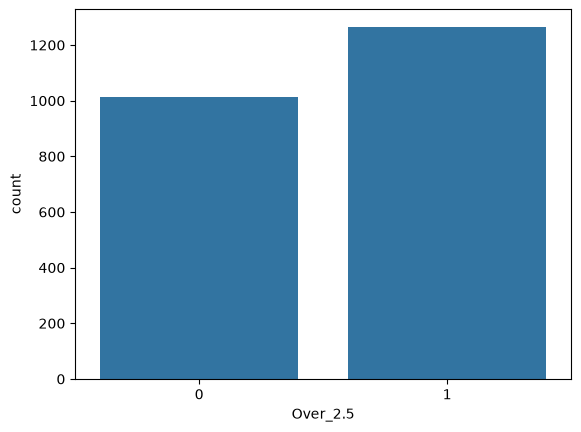

In [963]:
sns.countplot(
    data=df_PL_Master,
    x="Over_2.5"
)

#### The target variable shows a balanced class distribution 
#### 1265 Over 2.5
#### 1015 under 2.5
#### This should reduce any risk of model bias towards a dominant class

## Create a Boxplot to show Over 2.5

<Axes: xlabel='Over_2.5', ylabel='Total_Shots_On_Target'>

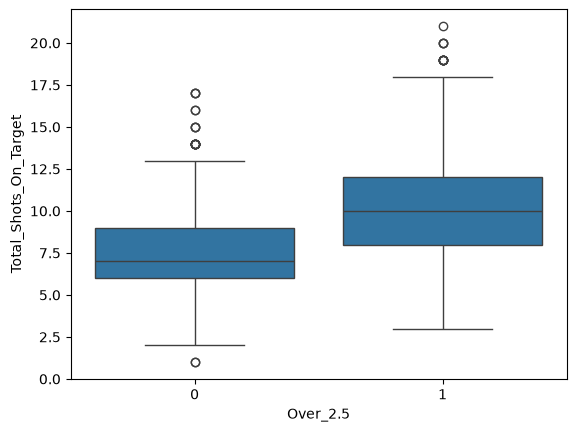

In [964]:
sns.boxplot(
    data=df_PL_Master,
    x="Over_2.5",
    y="Total_Shots_On_Target"
)

Analysis of the above Boxplot, suggests that more shots on target tend to have a higher correlation to over 2.5 goals (1)

## Create a Correlation heatmap

In [965]:
df_Corr = df_PL_Master[
    ["Over_2.5",
     "Total_Corners", 
     "Total_Shots_On_Target", 
     "HT_Home_Goals", 
     "HT_Away_Goals", 
     "HT_Goals", 
     "Home_Shots_On_Target", 
     "Away_Shots_On_Target",
     "Home_Corners",
     "Away_Corners"
    ] 
    ].corr()

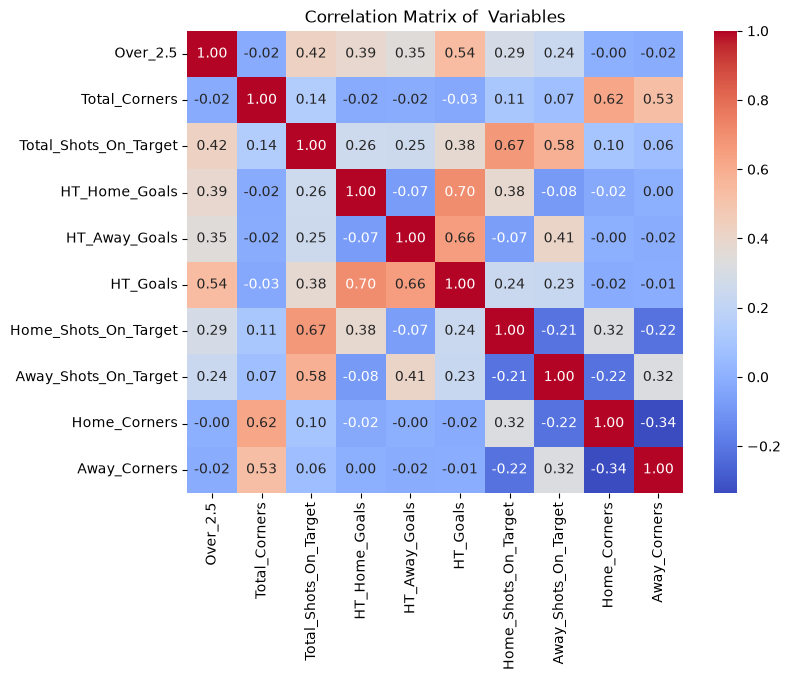

In [966]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    df_Corr,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Matrix of  Variables")

plt.show()

The above heatmap shows strong correlation to Over 2.5 Goals from:

Half Time Goals 0.54   
Half Time Home Goals 0.39   
Half Time Away Goals 0.35   
Total Shots on Target 0.42  

Half Time goals  0.54 indicates that first half goals are likely to finish with over 2.5 goals at the end of the game  

However, surprisingly the number of corners does not have a positive correlation to over 2.5 goals


#### Create a Histogram of Total Goals

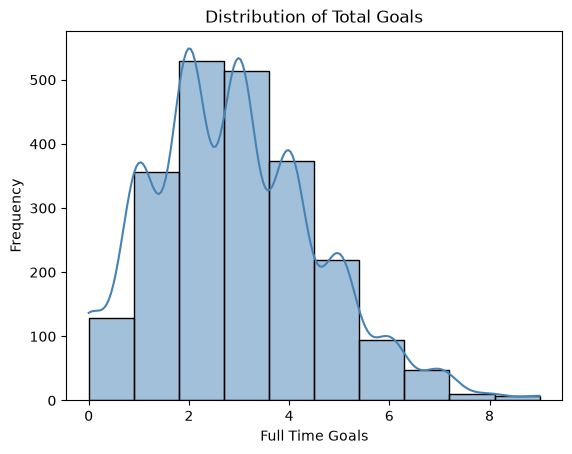

In [967]:
sns.histplot(
    data=df_PL_Master,
    x="FT_Goals", 
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Total Goals")
plt.xlabel("Full Time Goals")
plt.ylabel("Frequency")
plt.show()


The distribution of total goals is positively skewed

Most matches produce 1-4 goals per game

Matches with more than 6 goals are relatively rare

The histogram demonstrates that the target variable of over 2.5 goals is appropriate for classification


Check Normality (using Shapiro_Wilk_test)

In [968]:
from scipy import stats 
from scipy.stats import norm # for normality test 

In [969]:
stat, p_value = stats.shapiro(df_PL_Master["FT_Goals"])

print(stat,p_value)

0.9495699789949624 2.634908074477783e-27


In [970]:
if p_value >= 0.05:
    print("Sample appears to be normally distributed.")
else:
    print("Sample does not appear to be normally distributed.")
    

Sample does not appear to be normally distributed.


Create a GroupBy analysis of Half Time goals, Total Shots on Target and Total Corners against the Over 2.5 Outcome

#### GroupBy Results

In [971]:
df_PL_Master.groupby("Over_2.5")[
        ["HT_Goals",
         "Total_Shots_On_Target",
        "Total_Corners"]
    ].mean()

,HT_Goals,Total_Shots_On_Target,Total_Corners
Over_2.5,,,
0,0.622660,7.464039,10.374384
1,1.837154,10.110672,10.256126


Half Time Goals Analysis  

Matches that finished under 2.5 goals, had an average of 0.64 half time goals  

Whereas matches that finished over 2.5, had an average of 1.84 half time goals  

Indicating that half time goals may be a good indicator of higher scoring games

Shots on Target Analysis  

Matches with over 2.5 goals showed a higher shots on target 10.11 than the 7.46 for under 2.5  

This also indicates a positive relationship between attacking play and over 2.5 goals  

This also aligns with the heatmap correlation of 0.42

Total Corners Analysis

Total Corners had approximately 10 for both over 2.5 and under 2.5.  This suggests little influence between the number of corners and goals per game

#### Exploratory Data Analysis -  Conclusion

The analysis has identified that half time goals along with shots on target have a higher correlation to games ending in more than 2.5 goals.  
In contrast the corners statistics showed little correlation, indicating that attacking action seems to be a more useful predictor overall

In [972]:
# df_PL_Master.to_csv("Premier League Master.csv", index=False)

#### Classification Model Testing

Three Classification models will be selected for this project.  

Gaussian Naive Bayes was chosen as it performs well with numerical predictor variables.  

Random Forest was selected due to its capability of identifying non-linear relationships between football game statistics and the Target variable (Over 2.5 goals).  It combines multiple decision Trees, reducing the risk of overfitting, whilst improving predictive accuracy.   

K-Nearest Neighbours was selected as it classifies observations based on similarity to neighbouring matches within the dataset.  This makes it useful for identifying similar match patterns and provides a comparision to the other, more advanced approaches.  



The Target variable was created earlier as a binary classification, where 3 or more golas =1, else =0

Import sklearn libraries

In [973]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report


###  1. The Gaussian Naive Bayes model

Run the model prior to PCA

Carry out Train Test split and Scale the data using Standard scaler

For the Gaussian Naive Bayes Model, I will run the 5%, 15% and 25% Test split cases.  

The PCA and other choosed Models will run the 25% test split

In [974]:
No_Columns = df_PL_Master.shape[1]
print (f"The original number of columns is : {No_Columns}")

The original number of columns is : 17


I now need to split the dataset into the independent and dependent variables.  
I also need to bring forward only the numeric values from the original dataset.  
To prevent data leakage, it is important to remove any values that will provide the actual results, such as Over_2.5 variable itself, Full time goals, Full time home goals and Full time away goals.  

The dependent Y Target is "Over 2.5" column
    

In [975]:
# Spliting the dataset into independent and dependent variables

# Use numeric variables only from the daatasett
X = df_PL_Master.select_dtypes(include=[np.number])

# Remove the target_code and other associated columns that give the goals scored, to prevent data leakage
X = X.drop(columns=[
     "Over_2.5",
     "FT_Home_Goals",
     "FT_Away_Goals",
     "FT_Goals"
    ])


# Dependent variables (Target)
y = df_PL_Master["Over_2.5"]

num_rows = X.shape[0]
num_features = X.shape[1]

print(f" The number of rows: {num_rows} ")
print(f" The number of numeric features selected was: {num_features} ")



 The number of rows: 2280 
 The number of numeric features selected was: 9 


Run a 5% Test Split

In [976]:
# Splitting the dataset into the Training set and Test set

# test _size = 0.05 = 5%, random_state =82, is an arbitory number set throughout the tests
# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.05, 
    random_state = 82,
    stratify=y
    )

# Display rows and columns
X_train.shape, X_test.shape

((2166, 9), (114, 9))

In [977]:
# Feature Scaling to bring the variable in a single scale


# Create an initialise an object sc by calling a method StandardScaler()
sc = StandardScaler()

# Train the model by calling a method fit_transform
X_train = sc.fit_transform(X_train)

# Store the transformed data into X_test
X_test = sc.transform(X_test)

In [978]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train,
    y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[ 964.,1202.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.45,0.55]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 9)","[[-0.43,-0.38,-0.32,...,-0.6 ,-0.47, 0.01], [ 0.35, 0.31, 0.26,..., 0.48, 0.38,-0.01]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 9)","[[0.41,0.4 ,0.74,...,0.35,0.74,1. ], [1.21,1.27,1.06,...,1. ,0.89,1. ]]"


In [979]:
# Predicting the Test set results
y_pred_nb = nb_model.predict(
    X_test)

In [980]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred_nb)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[0, 0],
       [1, 0],
       [0, 0],
       [0, 0],
       [1, 1],
       [0, 1],
       [1, 1],
       [0, 0],
       [0, 0],
       [0, 0],
       [1, 1],
       [0, 0],
       [1, 0],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 0],
       [1, 0],
       [0, 0],
       [1, 1]])

In [981]:
score = accuracy_score(
    y_test, 
    y_pred_nb)


print(f"Accuray Score for a 5% Test split is : {score:.2%} ")

Accuray Score for a 5% Test split is : 81.58% 


In [982]:
print(classification_report(
    y_test,
    y_pred_nb)
)

              precision    recall  f1-score   support

           0       0.73      0.92      0.82        51
           1       0.92      0.73      0.81        63

    accuracy                           0.82       114
   macro avg       0.83      0.83      0.82       114
weighted avg       0.84      0.82      0.82       114



Run a 15% Test Split

In [983]:
# Splitting the dataset into the Training set and Test set


# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.15, 
    random_state = 82,
    stratify=y
    )

# Display rows and columns
X_train.shape, X_test.shape

((1938, 9), (342, 9))

In [984]:
# Feature Scaling to bring the variable in a single scale


# Create an initialise an object sc by calling a method StandardScaler()
sc = StandardScaler()

# Train the model by calling a method fit_transform
X_train = sc.fit_transform(X_train)

# Store the transformed data into X_test
X_test = sc.transform(X_test)

In [985]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train,
    y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[ 863.,1075.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.45,0.55]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 9)","[[-0.43,-0.38,-0.33,...,-0.59,-0.47, 0.01], [ 0.34, 0.31, 0.26,..., 0.48, 0.38,-0.01]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 9)","[[0.41,0.4 ,0.75,...,0.35,0.75,1. ], [1.21,1.27,1.04,...,1.01,0.88,1. ]]"


In [986]:
# Predicting the Test set results
y_pred_nb = nb_model.predict(
    X_test)

In [987]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred_nb)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[0, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [1, 0],
       [1, 1],
       [1, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 1]])

In [988]:
score = accuracy_score(
    y_test, 
    y_pred_nb)


print(f"Accuracy Score for a 15% Test split is : {score:.2%} ")

Accuracy Score for a 15% Test split is : 79.24% 


In [989]:
print(classification_report(
    y_test,
    y_pred_nb)
)

              precision    recall  f1-score   support

           0       0.73      0.85      0.78       152
           1       0.86      0.75      0.80       190

    accuracy                           0.79       342
   macro avg       0.79      0.80      0.79       342
weighted avg       0.80      0.79      0.79       342



Run a 25% Test Split

In [990]:
# Splitting the dataset into the Training set and Test set


# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.25, 
    random_state = 82,
    stratify=y
    )

# Display rows and columns
X_train.shape, X_test.shape

((1710, 9), (570, 9))

In [991]:
# Feature Scaling to bring the variable in a single scale


# Create an initialise an object sc by calling a method StandardScaler()
sc = StandardScaler()

# Train the model by calling a method fit_transform
X_train = sc.fit_transform(X_train)

# Store the transformed data into X_test
X_test = sc.transform(X_test)

In [992]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train,
    y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[761.,949.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.45,0.55]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 9)","[[-0.44,-0.38,-0.33,...,-0.6 ,-0.47, 0.01], [ 0.35, 0.31, 0.27,..., 0.48, 0.38,-0.01]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 9)","[[0.41,0.4 ,0.74,...,0.34,0.75,0.96], [1.2 ,1.27,1.05,...,1.01,0.88,1.03]]"


In [993]:
# Predicting the Test set results
y_pred_nb = nb_model.predict(
    X_test)

In [994]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred_nb)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[1, 1],
       [0, 0],
       [0, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [0, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 1],
       [1, 0],
       [1, 1],
       [1, 1]])

In [995]:
score = accuracy_score(
    y_test, 
    y_pred_nb)


print(f"Accuracy Score for a 25% Test split is : {score:.2%} ")

Accuracy Score for a 25% Test split is : 76.49% 


In [996]:
print(classification_report(
    y_test,
    y_pred_nb)
)

              precision    recall  f1-score   support

           0       0.70      0.83      0.76       254
           1       0.84      0.71      0.77       316

    accuracy                           0.76       570
   macro avg       0.77      0.77      0.76       570
weighted avg       0.78      0.76      0.77       570



### Test Split evaluation

The train-test configurations consisted of 5%, 15% and 25% test datasets.  

Stratified sampling was applied (stratify=y) to maintain consistent class distribution between the training and testing datasets.  

Standardisation was performed only on the training data, to ensure that information from the test set was not introduced, avoiding data leakage.  

    

### Results Analysis
The Gaussian Naive Bayes model achieved an accuracy of:  

5% Test split = 81.58%  

15% Test split = 79.24%  

25% Test split = 76.49%

The results remained relatively consistent and the model performed well across unseen data, suggesting that it did not appear to suffer from any substantial overfitting


### Run the Model after PCA  

25% Test Split is selected for PCA as it provides the largest test dataset

In [997]:
# Splitting the PCA  dataset into the Training set and Test set


# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.25, 
    random_state = 82,
    stratify=y
    )
    

# Scale training data only
scaler = StandardScaler()


# Train the model by calling a method fit_transform
X_train_scaled = scaler.fit_transform(X_train)
# Store the transformed data into X_test
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.90) 

# Display rows and columns
X_train.shape, X_test.shape

# Train the model by calling a method fit_transform
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [998]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train_pca,
    y_train)

# Predicting the Test set results
y_pred_pca = nb_model.predict(X_test_pca)

In [999]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred_pca)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[1, 1],
       [0, 0],
       [0, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [0, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 1],
       [1, 0],
       [1, 1],
       [1, 1]])

In [1000]:
score = accuracy_score(
    y_test, 
    y_pred_pca)


print(f"The PCA Accuracy Score is : {score:.2%} ")

The PCA Accuracy Score is : 75.96% 


In [1001]:
print(classification_report(
    y_test,
    y_pred_pca)
)

              precision    recall  f1-score   support

           0       0.71      0.78      0.74       254
           1       0.81      0.74      0.77       316

    accuracy                           0.76       570
   macro avg       0.76      0.76      0.76       570
weighted avg       0.76      0.76      0.76       570



In [1002]:
print(f"The number of numeric columns in the dataset, prior to PCA was: {num_features} ")
print(f"The number of components retained after PCA was: {pca.n_components_} ")    
print(f"The percentage of Variance retained was: {pca.explained_variance_ratio_.sum()*100:.2f} %") 

The number of numeric columns in the dataset, prior to PCA was: 9 
The number of components retained after PCA was: 5 
The percentage of Variance retained was: 94.63 %


### PCA Analysis
Principal Component Analysis (PCA) was the applied dimensionality reduction technique.  

In line with previous tests, it was kept at 25% test split, as this provided the largest sample.  

PCA was set to retain 90% of the total variance contained within the original dataset.  

Prior to PCA, the numeric columns used in the test split dataset was 9.  PCA reduced the total columns to 5, whilst still retaining 94.63% of the total variance.

The PCA model returned an accuracy score of 75.96%. This suggests that PCA was able to reduce the dataset and still produce comparable predictive performance.  
    
        

#### Conclusion with The Gaussian Naive Bayes model and PCA 

Overall, the results suggest that half time goals and shots on target provide useful predictors for identifying the over 2.5 result.

PCA also demonstrated that dimensionality reduction can maintain comparable prediction performance.    

### 2. Random Forest Classification Model

Run the data using the 25% Test Split

Add Libraries

In [1003]:
# from sklearn.tree import DecisionTreeClassifier       # Import Decision Tree Classifier
from sklearn import metrics                           # Import scikit-learn metrics module for accuracy calculation
from sklearn import tree 
from sklearn.ensemble import RandomForestClassifier   #Import Random Forest Model

import warnings
warnings.filterwarnings('ignore')                     # We can suppress the warnings

In [1004]:
# Spliting the dataset into independent and dependent variables

# Use numeric variables only from the daatasett
X = df_PL_Master.select_dtypes(include=[np.number])

# Features
# Remove the target_code and other associated columns that give the goals scored, to prevent data leakage
X = X.drop(columns=[
     "Over_2.5",
     "FT_Home_Goals",
     "FT_Away_Goals",
     "FT_Goals"
    ])


# Dependent variables (Target)
y = df_PL_Master["Over_2.5"]


# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size = 0.25,  
                                                    random_state = 82,
                                                    stratify=y) 

In [1005]:
#Create a RandomForest Classifier
rf = RandomForestClassifier(n_estimators = 1000) 

#Train the model using the training sets 
rf.fit(X_train, 
       y_train)

y_pred_rf = rf.predict(X_test)

In [1006]:
# Print Accuracy rounded upto 2 decimal places
rf_score = accuracy_score(
    y_test, 
    y_pred_rf)


print(f"The Random Forest Accuracy score is : {rf_score:.2%} ")


The Random Forest Accuracy score is : 74.91% 


In [1007]:
print(classification_report(
    y_test,
    y_pred_rf)
)

              precision    recall  f1-score   support

           0       0.72      0.71      0.72       254
           1       0.77      0.78      0.78       316

    accuracy                           0.75       570
   macro avg       0.75      0.75      0.75       570
weighted avg       0.75      0.75      0.75       570



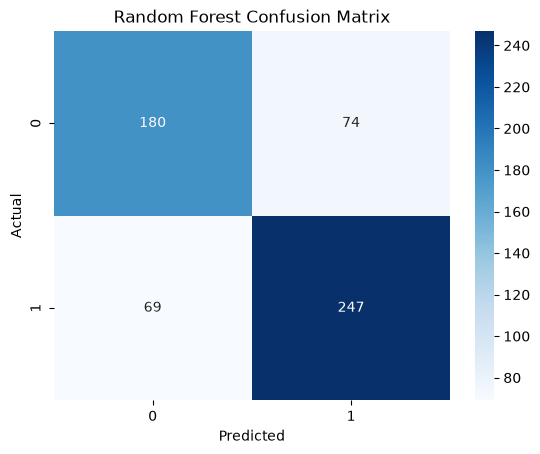

In [1008]:
from sklearn.metrics import confusion_matrix

# Call a method predict by using an object classifier 'cls_svm'
y_predict = rf.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, 
            annot = True,
            fmt='d',
            cmap='Blues')

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### Create a GridSearchCV for Hyperparameter Tuning

In [1009]:
# GridSearchCv is Hyperparameter Tuning that uses cross-validation behind the scenes
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state = 82),
    {
       "n_estimators": [100, 200],
        "max_depth": [10, 20],
        "min_samples_split": [2, 5]
    }, 
    cv = 5

)


rf_grid.fit(X_train, y_train)

print("Random Forest GridSearchCV Results")
print("-" * 40)
print(f"Best Parameters: {rf_grid.best_params_} ")
print(f"Best Cross Validation Accuracy: {rf_grid.best_score_:.2%}")

Random Forest GridSearchCV Results
----------------------------------------
Best Parameters: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100} 
Best Cross Validation Accuracy: 76.67%


### GridSearchCV Analysis

The original Random Forest Accuracy score is : 74.74% 

GridSearchCV was applied to the Random Forest Classifier and the optimal parameter settings identified were:
n_estimators = 100  

max_depth = 10  

min_samples_split = 5  

The model achieved a mean Cross Validation Accuracy of 76.67%, demonstrating that modest improvements in predictive performance can be achieved through hyperparameter tuning.

### 3. KNN Model

In [1010]:
# Import knearest neighbors Classifier model
from sklearn.neighbors import KNeighborsClassifier

# Import the confusion Matrix for KNN
from sklearn.metrics import confusion_matrix

# Import the GridSearchCv

from sklearn.model_selection import GridSearchCV

In [1011]:
# Spliting the dataset into independent and dependent variables

# Use numeric variables only from the daatasett
X = df_PL_Master.select_dtypes(include=[np.number])

# Features
# Remove the target_code and other associated columns that give the goals scored, to prevent data leakage
X = X.drop(columns=[
     "Over_2.5",
     "FT_Home_Goals",
     "FT_Away_Goals",
     "FT_Goals"
    ])


# Dependent variables (Target)
y = df_PL_Master["Over_2.5"]


# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size = 0.25,  
                                                    random_state = 82, 
                                                    stratify=y) 

In [1012]:
# Create KNN Classifier
kNN = KNeighborsClassifier(n_neighbors = 10)

# Train the model using the training sets
kNN.fit(X_train, 
        y_train)

# Predict the response for test dataset
y_pred_knn = kNN.predict(X_test)

In [1013]:
# Print Accuracy rounded upto 2 decimal places
knn_score = accuracy_score(
    y_test, 
    y_pred_knn)


print(f"The KNN Accuracy score is : {knn_score:.2%} ")

The KNN Accuracy score is : 71.40% 


In [1014]:
# Display the classification report
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.66      0.73      0.69       254
           1       0.76      0.70      0.73       316

    accuracy                           0.71       570
   macro avg       0.71      0.72      0.71       570
weighted avg       0.72      0.71      0.71       570



#### KNN Confusion Matrix

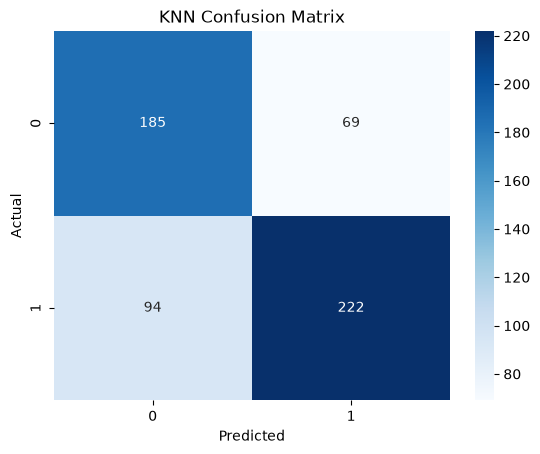

In [1015]:
from sklearn.metrics import confusion_matrix

# Call a method predict by using an object classifier 'cls_svm'
y_predict = kNN.predict(X_test)

# Calculate cm by calling a method named as 'confusion_matrix'
cm = confusion_matrix(y_test, y_predict)

# Call a method heatmap() to plot confusion matrix
sns.heatmap(cm, 
            annot = True,
            fmt='d',
            cmap='Blues')

plt.title("KNN Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [1016]:
neighbors = np.arange(1, 10)                  # number of neighbors
train_accuracy = np.zeros(len(neighbors))     # Declare and initialise the matrix
test_accuracy = np.zeros(len(neighbors))      # Declare and initialise the matrix

In [1017]:
for i, k in enumerate(neighbors):                          # for loop that checks the model for neighbor values 1, 2, 3, ..., 10
    kNN = KNeighborsClassifier(n_neighbors = k)            # Initialise an object knn using KNeighborsClassifier method

    # Fit the model
    kNN.fit(X_train, y_train)                              # Call fit method to implement the ML KNeighborsClassifier model

    # Compute accuracy on the training set
    train_accuracy[i] = kNN.score(X_train, y_train)        # Save the score value in the train_accuracy array

    # Compute accuracy on the test set
    test_accuracy[i] = kNN.score(X_test, y_test)           # Save the score value in the train_accuracy array

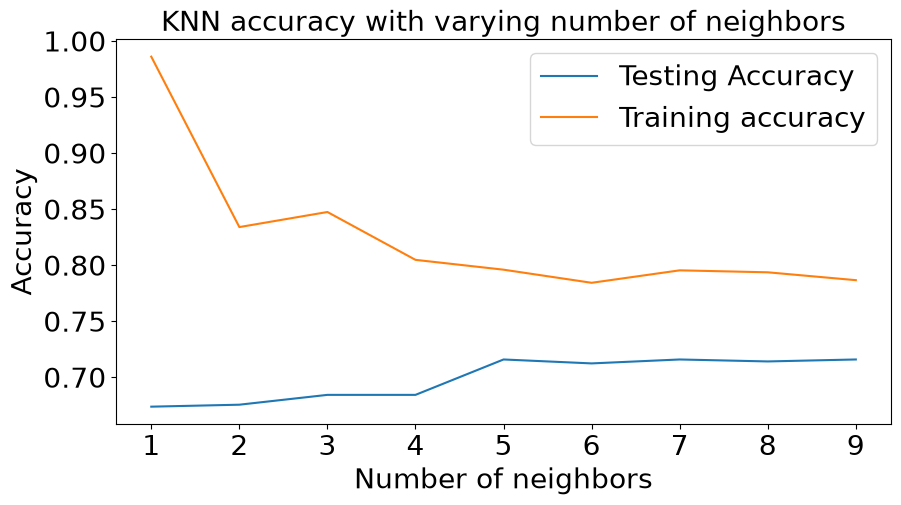

In [1018]:
plt.figure(figsize = (10, 5))
plt.title('KNN accuracy with varying number of neighbors', fontsize = 20)
plt.plot(neighbors, test_accuracy, label = 'Testing Accuracy')
plt.plot(neighbors, train_accuracy, label = 'Training accuracy')
plt.legend(prop={'size': 20})
plt.xlabel('Number of neighbors', fontsize = 20)
plt.ylabel('Accuracy', fontsize = 20)
plt.xticks(fontsize = 20)
plt.yticks(fontsize = 20)
plt.show()

****

## Cross Validation
Show the results in table format for the 3 models, running the 25% Test Split    

1. Gaussian 
2. Random Forest 
3. KNN

Run a cross validation score to test for stability in case of overfitting

In [1019]:
# Add Libraries
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

In [1020]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, random_state = 82)

In [1021]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=10),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=82),
    "Gaussian Naive Bayes" : GaussianNB(),

}

In [1022]:

results = []
for name, classifier in classifiers.items():
    # Train the classifier
    classifier.fit(X_train, y_train)
    
    # Predict on the test set
    y_pred = classifier.predict(X_test)
    
    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # Append results
    results.append([name, accuracy, precision, recall, f1_score])

In [1023]:
# Convert results to DataFrame for easy viewing
metrics_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"])
print("Model Performance Metrics on the 25% Test Split :")
print(metrics_df)

Model Performance Metrics on the 25% Test Split :
                  Model  Accuracy  Precision    Recall  F1 Score
0   k-Nearest Neighbors  0.705263   0.705747  0.705263  0.705427
1         Random Forest  0.759649   0.759495  0.759649  0.759174
2  Gaussian Naive Bayes  0.777193   0.778702  0.777193  0.777409


In [1024]:
# Cross-validation for accuracy on the full dataset
cv_results = []
for name, classifier in classifiers.items():
    cv_scores = cross_val_score(classifier, X, y, cv=5, scoring='accuracy')
    cv_results.append([name, cv_scores.mean()])

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results, columns=["Model", "Mean CV Accuracy"])
print("\nCross-Validation Accuracy Scores:")
print(cv_results_df)


Cross-Validation Accuracy Scores:
                  Model  Mean CV Accuracy
0   k-Nearest Neighbors          0.723246
1         Random Forest          0.747368
2  Gaussian Naive Bayes          0.762719


### Cross-Validation Results

Cross-Validation as carried out to test the stability of the models.  The dataset was divided into five folds, during each iteration process, one fold was the validation set and the remaining four folds were the training sets, allowing every observation to be used for training and validation.   

The mean accuracy across the five fold was used to validate the models stability.  

Gaussian Naive Bayes achieved the highest mean cross validation score of 76.27%.  The results show a consistent performance between the model test set results and cross validation results, suggesting that any overfitting was not observed.  The models achieved a significantly higher accuracy than a random result and this is suggesting that any severe underfitting was also not observed.

Note: Cross-Validation is used to assess the reliability and general performance of the machine learning models.  GridSearchCV was applied to the Random Forest Model to perform Hyperparameter Tuning.  GridSearchCV uses cross-validation internally to evaluate multiple parameter combinations and identify the settings that produce the best predictive accuracy.

****

### Conclusion

The results suggest that half time goals and shots on target provide useful predictors for identifying matches likely to finish with over 2.5 goals.  
The Gaussian Naive Bayes classifier achieved the best performance with 76.49% accuracy, using the 25% Test Split.  
Random Forest produced similar results of 74.91%, suggesting that the more complex models did not improve prediction for my dataset.  
K-Nearest Neighbours (KNN) produced the lowest accuracy score of 71.4%, suggesting that distance-based models are less successful in predicting Football Goals per game.

PCA also demonstrated that dimensionality reduction can maintain comparable prediction performance.   
Five fold cross-validation confirmed the stability of the results, again with Gaussian Naive Bayes producing the highest mean accuracy score of 76.27%.  Similar results between the test sets and cross-validation suggest that the models perform well to unseen data with no significant evidence of overfitting or underfitting.  
    
Overall, the results show that machine learning techniques can be successfully applied to predict over 2.5 goals in the Premier League, with Gaussian Naive Bayes showing the most promising predictive accuracy.  

.

****

### References

Football-Data.co.uk (2026) Football Results and Betting Data. Available at:
https://football-data.co.uk/data 
(accessed: 1 October 2026)

datacamp (2026) source:  https://www.datacamp.com/tutorial/random-forests-classifier-python
(Accessed 04/11/2026)

Pandas.org (2026) source: https://pandas.pydata.org/pandas-docs/stable/user_guide/merging.html
(Accessed 22/10/2026)

CCT College Dublin (2026) Data Preparation Module Notes. Available via Moodle 
(Accessed: 10 October 2026)

CCT College Dublin (2026) Statistical Techniques Module Notes. Available via Moodle (Accessed: 24 October 2026)

CCT College Dublin (2026) Machine Learning Module Notes. Available via Moodle 
(Accessed: 1 October 2026)

Python for Machine Learning & Data Science Masterclass by Pierian Data. Available at: www.udemy.com 
(Accessed: 15 October 2026)

Microsoft (2026) Microsoft Copilot.  Available at https://copilot.Microsoft.com
(Accessed: 1st November 2026)





End Of Analysis